# 9-5. GARCH·SV 동시최적화 구현과 검증

**전체 계획** (auto_arima 기반, 이제 GARCH/SV를 추가)

1. `9-1`~`9-4`: auto_arima 기반 d 고정, p,q 선택, 원/로그 스케일의 리샘플링 vs 자체 구간
2. **`9-5`: GARCH·SV 동시최적화 구현과 검증** (이 노트북)
3. `9-6`, `9-7`: GARCH의 원/로그 스케일 (9-3, 9-4 과정)
4. `9-8`, `9-9`: SV의 원/로그 스케일 (9-3, 9-4 과정)
5. `9-10`: auto_arima vs GARCH vs SV 종합 비교

공통 데이터와 평가 설정은 `9-1`의 0절을 따른다.

**이 노트북의 목적**: 구간·성능 비교(9-6~)에 들어가기 전에 모델 구현이 맞는지, 적합이 안정적인지, auto_arima와 점예측·계수가 어떻게 다른지 확인한다.

**모델**
- **AR단독(기준선)**: `auto_arima`(d=1, **AR만 허용**, AICc, p 최대 3, 절편 없음) -- GARCH/SV와 평균식 종류가 같아서 차이가 "변동성 모형과 동시최적화"에서만 오게 한다.
- **GARCH 동시**: AR(p)와 GARCH(1,1)을 한 우도로 추정(`arch`, 상수항 없음).
- **SV 동시**: AR(p)와 SV(1)을 한 우도로 추정(직접 구현한 QML + 칼만필터, 평균 제거 없음).

**AR 차수 p 선택**: 동시최적화의 조건부우도는 p를 바꾸면 우도 계산 표본 수가 달라져 AIC로 p를 고를 수 없다(`0923_0930/8-3`). 그래서 **origin마다 AR단독 `auto_arima`(정확우도, AICc)가 고른 p를 GARCH/SV에 그대로 쓴다.** 그 시점까지의 데이터만 쓰므로 누설이 없다.

**origin 표기**: `origin 35 (훈련 2011Q1~2019Q3, 예측 2019Q4~2020Q3)`처럼 훈련·예측 기간을 함께 적는다.


In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import pmdarima as pm
from arch.univariate import ARX, ZeroMean, GARCH
from scipy import stats
from scipy.optimize import minimize

H, MIN_TRAIN, INITIAL_CALIB, ALPHA = 4, 20, 15, 0.10
Z = stats.norm.ppf(1 - ALPHA / 2)
D = 1
XI_MEAN, XI_VAR, MAX_PHI = -1.2704, np.pi ** 2 / 2, 0.97
P_MAX = 3

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
data = raw[["quarter", "X3_l1"]].dropna().reset_index(drop=True)
quarters, vals = data["quarter"].values, data["X3_l1"].values.astype(float)
var_std = vals.std()
scored_origins = list(range(MIN_TRAIN, len(vals) - H + 1))[INITIAL_CALIB:]
FIRST = scored_origins[0]


def label(o):
    return f"origin {o} (훈련 {quarters[0]}~{quarters[o - 1]}, 예측 {quarters[o]}~{quarters[o + H - 1]})"


def period(o):
    return {"훈련 기간": f"{quarters[0]}~{quarters[o - 1]}", "예측 기간": f"{quarters[o]}~{quarters[o + H - 1]}"}


print(f"전체 {len(vals)}분기, 채점 origin {len(scored_origins)}개, d={D} 고정")
print("첫 origin:", label(FIRST))
print("마지막 origin:", label(scored_origins[-1]))


전체 60분기, 채점 origin 22개, d=1 고정
첫 origin: origin 35 (훈련 2011Q1~2019Q3, 예측 2019Q4~2020Q3)
마지막 origin: origin 56 (훈련 2011Q1~2024Q4, 예측 2025Q1~2025Q4)


## 1. 구현

세 모델의 예측 함수를 정의한다. 모두 **차분한 시계열에 AR(p)** 를 적합하고, 예측을 수준으로 되돌린다. 구현에서 이전(`0923_0930`)에 겪은 두 문제를 처음부터 막았다.

- **σ 전파**: h단계 수준 예측오차의 분산은 단계별 분산의 누적합이 아니라 `Σ ψ_(h-i)² x (i단계 오차분산)`이다(ψ는 AR 충격반응을 d번 누적합한 값, `level_sigma`). GARCH/SV는 단계별 오차분산이 다르게 나오고, AR단독은 일정한 분산을 쓴다.
- **드리프트 없음**: 세 모델 모두 상수항·평균 복원을 두지 않는다(GARCH `constant=False`, SV는 평균 제거 없음, AR단독 `with_intercept=False`).


In [2]:
def difference(values, d):
    x = np.asarray(values, dtype=float)
    hist = []
    for _ in range(d):
        hist.append(x.copy())
        x = np.diff(x)
    return x, hist


def undiff_mean(diff_fc, hist, d):
    fc = np.asarray(diff_fc, dtype=float)
    for i in reversed(range(d)):
        fc = hist[i][-1] + np.cumsum(fc)
    return fc


def is_ar_stable(ar_coefs):
    p = len(ar_coefs)
    if p == 0:
        return True
    companion = np.zeros((p, p))
    companion[0, :] = ar_coefs
    if p > 1:
        companion[1:, :-1] = np.eye(p - 1)
    return np.max(np.abs(np.linalg.eigvals(companion))) < 0.999


def level_sigma(ar_coefs, d, innov_var):
    # ARIMA(p,d,0)의 h단계 수준 예측오차 표준편차 (innov_var[i] = (i+1)단계 오차분산)
    p = len(ar_coefs)
    psi = np.zeros(H)
    for j in range(H):
        psi[j] = 1.0 if j == 0 else sum(ar_coefs[k] * psi[j - 1 - k] for k in range(min(p, j)))
    for _ in range(d):
        psi = np.cumsum(psi)
    return np.sqrt(np.array([sum(psi[h - i] ** 2 * innov_var[i] for i in range(h + 1)) for h in range(H)]))


def sv_qml_negloglik(z_centered, phi, sigma_eta2):
    P0 = sigma_eta2 / (1 - phi ** 2) if abs(phi) < 0.999 else sigma_eta2 * 100
    h_pred, P_pred, loglik = 0.0, P0, 0.0
    for z in z_centered:
        F = P_pred + XI_VAR
        v = z - h_pred
        loglik += -0.5 * (np.log(2 * np.pi * F) + v ** 2 / F)
        K = P_pred / F
        h_filt, P_filt = h_pred + K * v, P_pred * (1 - K)
        h_pred, P_pred = phi * h_filt, phi ** 2 * P_filt + sigma_eta2
    return -loglik


def sv_residuals(y, ar):
    p = len(ar)
    return np.array([y[t] - sum(ar[i] * y[t - 1 - i] for i in range(p)) for t in range(p, len(y))])


def joint_sv_negloglik(params, y, p):
    ar, phi, s2 = params[:p], MAX_PHI * np.tanh(params[p]), np.exp(params[p + 1]) ** 2
    if not is_ar_stable(ar):
        return 1e10
    z = np.log(sv_residuals(y, ar) ** 2 + 1e-8)
    return sv_qml_negloglik(z - z.mean(), phi, s2)


def select_p(train):
    # AR단독 auto_arima(정확우도, AICc): d=1 고정, MA 없음, 절편 없음
    m = pm.auto_arima(train, d=D, seasonal=False, start_q=0, max_q=0, max_p=P_MAX, information_criterion="aicc",
                      with_intercept=False, suppress_warnings=True, error_action="ignore")
    return m.order[0], m


def ar_forecast(train, p, m):
    fc, conf = m.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
    par = dict(zip(m.arima_res_.model.param_names, m.arima_res_.params))
    ar = [par[f"ar.L{k}"] for k in range(1, p + 1)]
    return np.asarray(fc), (conf[:, 1] - conf[:, 0]) / (2 * Z), {"ar1": ar[0] if p else np.nan}


def garch_forecast(train, p):
    diff_train, hist = difference(train, D)
    am = ZeroMean(diff_train, rescale=False) if p == 0 else ARX(diff_train, lags=p, constant=False, rescale=False)
    am.volatility = GARCH(p=1, q=1)
    res = am.fit(disp="off")
    f = res.forecast(horizon=H, reindex=False)
    ar = [res.params[f"y[{k}]"] for k in range(1, p + 1)]
    fc = undiff_mean(f.mean.values[-1], hist, D)
    sig = level_sigma(ar, D, f.residual_variance.values[-1])
    return fc, sig, {"ar1": ar[0] if p else np.nan, "omega": res.params["omega"], "alpha": res.params["alpha[1]"], "beta": res.params["beta[1]"]}


def sv_forecast(train, p):
    y, hist = difference(train, D)
    res = minimize(joint_sv_negloglik, [0.0] * p + [1.5, np.log(0.3)], args=(y, p), method="Nelder-Mead", options={"maxiter": 3000})
    if not is_ar_stable(res.x[:p]) or res.fun >= 1e9:
        return None
    ar, phi, s2 = res.x[:p], MAX_PHI * np.tanh(res.x[p]), np.exp(res.x[p + 1]) ** 2
    z = np.log(sv_residuals(y, ar) ** 2 + 1e-8)
    zm = z.mean()
    P, h = s2 / (1 - phi ** 2), 0.0
    for x in z - zm:
        K = P / (P + XI_VAR)
        hf, Pf = h + K * (x - h), P * (1 - K)
        h, P = phi * hf, phi ** 2 * Pf + s2
    past = list(y[-p:]) if p else []
    mean_diff = []
    for _ in range(H):
        pred = sum(ar[i] * past[-1 - i] for i in range(p))
        mean_diff.append(pred)
        past.append(pred)
    v = [np.exp(zm - XI_MEAN + phi ** k * hf + (phi ** (2 * k) * Pf + s2 * sum(phi ** (2 * j) for j in range(k))) / 2) for k in range(1, H + 1)]
    return undiff_mean(mean_diff, hist, D), level_sigma(ar, D, v), {"ar1": ar[0] if p else np.nan, "phi_logvol": phi, "sigma_eta": np.sqrt(s2)}


## 2. AR 차수 p -- AR단독 auto_arima가 origin마다 선택

`auto_arima`(AR만, d=1, AICc, p 최대 3, 절편 없음)가 고른 p를 확인한다. p 최대 3은 훈련 표본이 35~56개로 작아 동시최적화의 안정성을 위해 둔 상한이다.


In [3]:
sel = {}
rows = []
for o in scored_origins:
    p, m = select_p(vals[:o])
    sel[o] = (p, m)
    rows.append({"origin": o, **period(o), "선택된 p": p})
ptab = pd.DataFrame(rows).set_index("origin")
display(ptab)
print("선택된 p 분포:", ptab["선택된 p"].value_counts().sort_index().to_dict())


,훈련 기간,예측 기간,선택된 p
origin,,,
35,2011Q1~2019Q3,2019Q4~2020Q3,1
36,2011Q1~2019Q4,2020Q1~2020Q4,1
37,2011Q1~2020Q1,2020Q2~2021Q1,1
38,2011Q1~2020Q2,2020Q3~2021Q2,1
39,2011Q1~2020Q3,2020Q4~2021Q3,1
40,2011Q1~2020Q4,2021Q1~2021Q4,1
41,2011Q1~2021Q1,2021Q2~2022Q1,1
42,2011Q1~2021Q2,2021Q3~2022Q2,1
43,2011Q1~2021Q3,2021Q4~2022Q3,1


선택된 p 분포: {1: 18, 2: 4}


## 3. 재현 검증 -- σ 전파 공식이 pmdarima와 일치하는가

`level_sigma`가 맞는지 확인한다. AR단독 `auto_arima` 적합에서 얻은 AR계수와 일정한 오차분산(`sigma2`)을 넣어 계산한 수준 σ가 pmdarima의 `conf_int`에서 나온 σ와 같아야 한다. GARCH/SV는 같은 `level_sigma`에 단계별 오차분산만 달리 넣는다.


In [4]:
diffs = []
for o in scored_origins:
    p, m = sel[o]
    par = dict(zip(m.arima_res_.model.param_names, m.arima_res_.params))
    ar = [par[f"ar.L{k}"] for k in range(1, p + 1)]
    mine = level_sigma(ar, D, np.full(H, par["sigma2"]))
    _, conf = m.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
    ref = (conf[:, 1] - conf[:, 0]) / (2 * Z)
    diffs.append(np.max(np.abs(mine - ref) / ref))
print("level_sigma와 pmdarima σ의 최대 상대 차이(22개 origin 중 최대):", f"{max(diffs):.2e}")


level_sigma와 pmdarima σ의 최대 상대 차이(22개 origin 중 최대): 4.91e-15


## 4. 22개 origin 적합 -- 수렴과 코너해

각 origin에서 세 모델을 적합한다(p는 2절의 값). 적합 실패와 코너해를 센다.

- **GARCH**: α+β ≥ 0.99(분산이 거의 발산)인 origin 수.
- **SV**: phi가 상한 근처(`|phi| >= MAX_PHI x 0.999`)이거나 σ_η < 0.01인 origin 수, 적합 실패(`None`) 수.


In [5]:
CACHE = "../cache/cache_95_joint_fit_df.pkl"
if os.path.exists(CACHE):
    fit = pd.read_pickle(CACHE)
else:
    rows = []
    for o in scored_origins:
        train, actual = vals[:o], vals[o:o + H]
        p, m = sel[o]
        outs = {"AR단독": ar_forecast(train, p, m)}
        for name, fn in [("GARCH동시", lambda: garch_forecast(train, p)), ("SV동시", lambda: sv_forecast(train, p))]:
            try:
                outs[name] = fn()
            except Exception:
                outs[name] = None
        for name, out in outs.items():
            if out is None:
                rows.append({"origin": o, "모델": name, "p": p, "성공": False})
                continue
            fc, sig, info = out
            rows.append({"origin": o, "모델": name, "p": p, "성공": True, **{f"fc{h + 1}": fc[h] for h in range(H)},
                         **{f"sig{h + 1}": sig[h] for h in range(H)}, **info,
                         "MSE": np.mean(((actual - fc) / var_std) ** 2)})
    fit = pd.DataFrame(rows)
    fit.to_pickle(CACHE)

print("적합 성공 수 (22개 중):")
print(fit.groupby("모델")["성공"].sum().astype(int).to_dict())
g = fit[(fit["모델"] == "GARCH동시") & fit["성공"]]
s = fit[(fit["모델"] == "SV동시") & fit["성공"]]
print(f"GARCH: alpha+beta>=0.99 origin {int(((g['alpha'] + g['beta']) >= 0.99).sum())}/{len(g)}")
corner = (s["phi_logvol"].abs() >= MAX_PHI * 0.999) | (s["sigma_eta"] < 0.01)
print(f"SV: phi 상한 근처 또는 sigma_eta<0.01 origin {int(corner.sum())}/{len(s)}")


적합 성공 수 (22개 중):
{'AR단독': 22, 'GARCH동시': 22, 'SV동시': 22}
GARCH: alpha+beta>=0.99 origin 11/22
SV: phi 상한 근처 또는 sigma_eta<0.01 origin 0/22


## 5. 점예측과 계수 비교

세 모델의 점예측이 얼마나 다른지, AR계수가 어떻게 다른지 본다. 차이는 `var_std`로 정규화한 평균 절대 차이이고, 같은 값이면 점예측이 동일하다는 뜻이다. MSE는 구간 평가 전에 보는 점예측 정확도 확인이다.


In [6]:
ok = fit[fit["성공"]]
wide_fc = {n: ok[ok["모델"] == n].set_index("origin")[[f"fc{h}" for h in range(1, H + 1)]] for n in ["AR단독", "GARCH동시", "SV동시"]}
common = wide_fc["AR단독"].index.intersection(wide_fc["GARCH동시"].index).intersection(wide_fc["SV동시"].index)
pairs = {"|AR-GARCH|": ("AR단독", "GARCH동시"), "|AR-SV|": ("AR단독", "SV동시"), "|GARCH-SV|": ("GARCH동시", "SV동시")}
gap = {}
for k, (a, b) in pairs.items():
    d_ = (wide_fc[a].loc[common].values - wide_fc[b].loc[common].values)
    gap[k] = {"평균 정규화 차이": np.abs(d_).mean() / var_std, "동일 비율(%)": 100 * (np.abs(d_) < 1e-6).mean()}
display(pd.DataFrame(gap).round(3))

coef = ok.groupby("모델")[["ar1"]].agg(["mean", "std"]).round(3)
display(coef)
print("점예측 MSE(22개 origin 평균, 정규화):")
display(ok.groupby("모델")["MSE"].mean().round(3).to_frame("MSE"))
print("적합 성공 origin만의 평균이며, 3모델 모두 성공한 origin 수:", len(common))


,|AR-GARCH|,|AR-SV|,|GARCH-SV|
평균 정규화 차이,0.08,0.316,0.241
동일 비율(%),0.00,0.000,0.000


ar1       
          mean    std
모델                   
AR단독     0.513  0.084
GARCH동시  0.425  0.088
SV동시    -0.051  0.016

점예측 MSE(22개 origin 평균, 정규화):


,MSE
모델,
AR단독,1.127
GARCH동시,1.067
SV동시,1.053


적합 성공 origin만의 평균이며, 3모델 모두 성공한 origin 수: 22


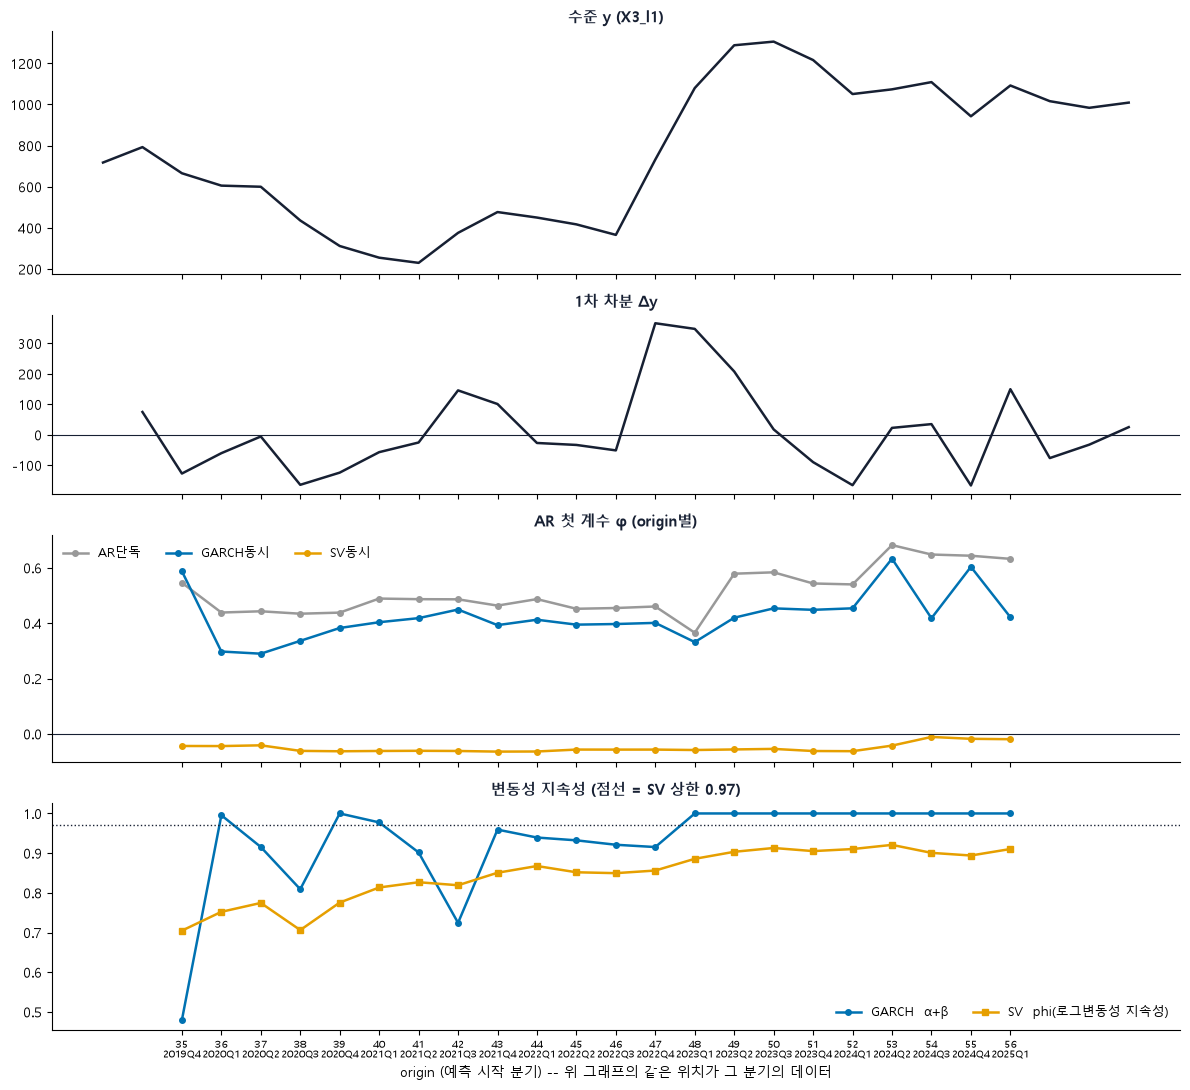

In [7]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

xl = [f"{o}\n{quarters[o]}" for o in scored_origins]
t0 = FIRST - 2
tt = np.arange(t0, len(vals))
dyv = np.diff(vals)
cols = {"AR단독": "#999999", "GARCH동시": "#0072B2", "SV동시": "#E69F00"}
fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True, gridspec_kw={"height_ratios": [1.5, 1.1, 1.4, 1.4]})
axes[0].plot(tt, vals[t0:], color="#172033", linewidth=1.8)
axes[0].set_title("수준 y (X3_l1)", fontsize=11, fontweight="bold", color="#172033")
axes[1].plot(tt[1:], dyv[t0:], color="#172033", linewidth=1.8)
axes[1].axhline(0, color="#172033", linewidth=0.8)
axes[1].set_title("1차 차분 Δy", fontsize=11, fontweight="bold", color="#172033")
for n, c in cols.items():
    sub = ok[ok["모델"] == n].set_index("origin")
    axes[2].plot(sub.index, sub["ar1"], marker="o", ms=4, color=c, linewidth=1.8, label=n)
axes[2].axhline(0, color="#172033", linewidth=0.8)
axes[2].set_title("AR 첫 계수 φ (origin별)", fontsize=11, fontweight="bold", color="#172033")
axes[2].legend(frameon=False, ncol=3, fontsize=9)
gs_ = ok[ok["모델"] == "GARCH동시"].set_index("origin")
ss_ = ok[ok["모델"] == "SV동시"].set_index("origin")
axes[3].plot(gs_.index, gs_["alpha"] + gs_["beta"], marker="o", ms=4, color="#0072B2", linewidth=1.8, label="GARCH  α+β")
axes[3].plot(ss_.index, ss_["phi_logvol"], marker="s", ms=4, color="#E69F00", linewidth=1.8, label="SV  phi(로그변동성 지속성)")
axes[3].axhline(MAX_PHI, color="#172033", linestyle=":", linewidth=1)
axes[3].set_title("변동성 지속성 (점선 = SV 상한 0.97)", fontsize=11, fontweight="bold", color="#172033")
axes[3].legend(frameon=False, ncol=2, fontsize=9)
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[3].set_xticks(scored_origins)
axes[3].set_xticklabels(xl, fontsize=7)
axes[3].set_xlabel("origin (예측 시작 분기) -- 위 그래프의 같은 위치가 그 분기의 데이터")
fig.tight_layout()
plt.show()


## 6. 결론

**GARCH·SV 동시최적화 구현은 맞고, 22개 origin 모두에서 안정적으로 적합된다.** 구간·성능 비교(9-6~)로 넘어간다.

- **σ 전파 검증 통과**: `level_sigma`가 pmdarima의 σ와 상대 차이 5e-15로 일치한다. GARCH/SV는 같은 공식에 단계별 분산만 달리 넣는다.
- **p 선택**: AR단독 auto_arima(AICc)가 22개 중 18개에서 p=1, 훈련에 급등이 포함된 마지막 4개(origin 53~56)에서 p=2를 골랐다. GARCH/SV에도 같은 p를 쓴다.
- **적합 성공**: AR단독·GARCH·SV 모두 22/22다. 코너해는 SV가 0/22(phi 0.70~0.92로 상한 0.97 아래), GARCH는 α+β≥0.99가 11/22다. 특히 훈련에 급등이 들어간 origin 48~56은 α+β가 거의 1.0이어서 분산이 평균으로 돌아오지 않는 경계 상태다(데이터 특성).
- **점예측은 세 모델이 서로 다르다**(동일 비율 0%):

| 쌍 | 평균 정규화 차이 |
|---|---|
| \|AR-GARCH\| | 0.080 |
| \|AR-SV\| | 0.316 |
| \|GARCH-SV\| | 0.241 |

  AR 첫 계수는 AR단독 0.513, GARCH 0.425, SV **-0.051**이다. SV의 AR계수가 0 근처인 것은 이전(`0923_0930/8-2`)과 같다. SV 우도가 로그변동성 경로를 맞추는 데 쓰여 점예측 정확도는 직접 보상하지 않는 구조 때문이며, SV의 점예측은 사실상 랜덤워크에 가깝다.
- **점예측 MSE**(정규화, 22개 평균): AR단독 1.127, GARCH 1.067, SV 1.053으로 차이는 작다. 구간 평가는 9-6부터 한다.

**한계**: 이 노트북은 구현 검증이고 구간 평가는 아니다. 훈련 35~56개로 GARCH가 경계(α+β≈1)에 붙는 origin이 많다. p 최대 3은 안정성을 위해 둔 상한이다. 22개 origin이 겹쳐 유의성은 검증하지 않았다.

**다음 단계**: `9-6`에서 GARCH의 원 스케일 리샘플링 vs 자체 7분위 구간을 `9-3` 과정으로 비교한다.
